In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchtsmixer import TSMixer
import os
import sys
import json
import glob
import pandas as pd
import PIL
from PIL import Image
import numpy as np
from torchvision import transforms
from torchinfo import summary
import cv2
from natsort import natsorted

sys.path.append("../unisal/")
import unisal

sys.path.append("..")
import utils
from models import Conv_tsmixer

import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
meta_path = '../../data/results/15frames_images'

# Reads images from the specified path
img_paths = natsorted(glob.glob(os.path.join(meta_path, "*.jpg")))
images = []
for img_path in img_paths:
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (384, 288))
    images.append(img)
    
# Read metadata of images

json_paths =  natsorted(glob.glob(os.path.join(meta_path, "*.json")))

metadata = []
for json_path in json_paths:
    with open(json_path, "r") as f:
        data = json.load(f)
        df = pd.DataFrame([data])
    metadata.append(df)

metadata = pd.concat(metadata, ignore_index=True)


In [3]:
metadata

,frame_number,horz_hmd_deg,vert_hmd_deg,giw_long,giw_lat,eih_x,eih_y,cropped_frame_filename,video_id,user_id,task_id
0,1,27.92,-22.84,33.87,-27.23,0.54,0.47,Video_8_User_3_Task_1_1,8,3,1
1,2,27.92,-22.84,33.87,-27.24,0.54,0.47,Video_8_User_3_Task_1_2,8,3,1
2,3,27.87,-22.87,33.76,-27.28,0.53,0.47,Video_8_User_3_Task_1_3,8,3,1
3,4,27.87,-22.82,33.78,-27.25,0.53,0.47,Video_8_User_3_Task_1_4,8,3,1
4,5,27.84,-22.83,33.77,-27.29,0.53,0.47,Video_8_User_3_Task_1_5,8,3,1
5,6,27.87,-22.88,33.83,-27.37,0.53,0.47,Video_8_User_3_Task_1_6,8,3,1
6,7,28.03,-22.85,34.02,-27.35,0.54,0.47,Video_8_User_3_Task_1_7,8,3,1
7,8,27.99,-22.83,34.02,-27.34,0.54,0.47,Video_8_User_3_Task_1_8,8,3,1
8,9,28.02,-22.86,34.12,-27.35,0.54,0.47,Video_8_User_3_Task_1_9,8,3,1
9,10,28.16,-22.80,34.32,-27.25,0.54,0.47,Video_8_User_3_Task_1_10,8,3,1


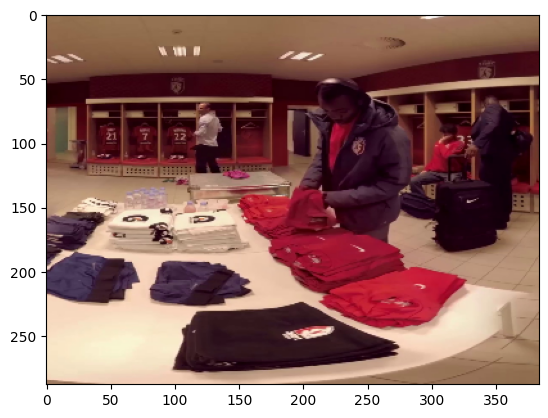

In [4]:

plt.imshow(images[0])

In [5]:
def preprocess(img):
    # img = np.ascontiguousarray(img[:, :, ::-1])

    preproc_cfg = {
        "out_size": [288, 384],
        "rgb_mean": (0.485, 0.456, 0.406),
        "rgb_std": (0.229, 0.224, 0.225),
    }
    transformations = [
        transforms.ToPILImage(),
        transforms.Resize(preproc_cfg["out_size"], interpolation=PIL.Image.LANCZOS),
        transforms.ToTensor(),
    ]
    if "rgb_mean" in preproc_cfg:
        transformations.append(
            
            transforms.Normalize(preproc_cfg["rgb_mean"], preproc_cfg["rgb_std"])
        )
    processing = transforms.Compose(transformations)
    tensor = processing(img)
    return tensor

def sal_process(smap):
    smap = (smap - np.min(smap)) / ((np.max(smap) - np.min(smap)))
    smap = (smap - 0.5) / 0.5 # Scale to [-1,1]
    return smap 


def calculate_angular_velocity(angles, sample_rate=30, vel_range=700):

    # Calculate the differences between consecutive angles
    angle_differences = np.diff(angles)

    # Compute angular velocity in deg per second
    angular_velocity = angle_differences * sample_rate

    # Clamp the angular velocity to the specified range
    angular_velocity = np.clip(angular_velocity, -vel_range, vel_range)

    # Add the first velocity again at the beginning to match the length of input angles
    angular_velocity = np.concatenate(([angular_velocity[0]], angular_velocity))

    return angular_velocity

def calculate_angle_diff(angles):
    angles_diff = np.diff(angles)
    angles_diff = np.concatenate(([0], angles_diff))
    return angles_diff

In [6]:
# Load models
class InputWrapper(nn.Module):
    def forward(self, x):
        if x.shape != (1, 3, 288, 384):
            raise ValueError(f"Expected input shape (1, 3, 288, 384), but got {x.shape}")
        return x.unsqueeze(0)

class WrappedUNISAL(nn.Module):
    def __init__(self, sal_path):
        super(WrappedUNISAL, self).__init__()
        self.input_wrapper = InputWrapper()
        self.unisal_model = unisal.model.UNISAL()
        self.unisal_model.load_state_dict(torch.load(sal_path))
        self.unisal_model.eval()  # Set to evaluation mode

    def forward(self, x):
        x = self.input_wrapper(x)
        return self.unisal_model(x)
    
# Prepare teh time series data and load saliency maps
timepoints = 15
salmapsps = 6
fps = 30
future_time = 200  # prediction in ms time
future_steps = int((fps * future_time) / 1000)
sal_frames_keep = int(timepoints / fps * salmapsps)
interval = int(fps / salmapsps)

sal_path = "../models/unisal.pth"
time_path = "../trained_models/conv_tsmixer_test_stadarized_6fituresteps_lr3/model_epoch_11_val_loss_0.1634.pth"  # conv_tsmixer_test_stadarized/model_epoch_9_val_loss_0.1763.pth"

unisal_model = WrappedUNISAL(sal_path)
# unisal_model.load_state_dict(torch.load(sal_path))
# unisal_model.eval()
unisal_model.to(device)

num_time_features = 4
conv_output_embeddings = 10
sequence_length = 15
prediction_length = future_steps
prediction_features = 2
time_model = Conv_tsmixer(
    num_time_features,
    conv_output_embeddings,
    sequence_length,
    prediction_length,
    prediction_features,
)
time_model.load_state_dict(torch.load(time_path))
time_model.eval()
time_model.to(device)


/home/cp/miniconda3/envs/access/lib/python3.9/site-packages/torch/functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3549.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Conv_tsmixer(
  (conv1): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(16, 8, kernel_size=(5, 5), stride=(1, 1))
  (bn2): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=72, out_features=10, bias=True)
  (Dropout): Dropout(p=0.5, inplace=False)
  (tsmixer): TSMixer(
    (mixer_layers): Sequential(
      (0): MixerLayer(
        (time_mixing): TimeMixing(
          (norm): TimeBatchNorm2d(210, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (fc1): Linear(in_features=15, out_features=15, bias=True)
        )
        (feature_mixing): FeatureMixing(
          (norm_before): TimeBatchNorm2d(210, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      

In [7]:
# Preprocess the data
# Preprocess each image in the batch
preprocessed_images = []

for j in range(len(images)):
    img = images[j]
    preprocessed_img = preprocess(img)
    preprocessed_images.append(preprocessed_img)

img_timeseries = torch.stack(preprocessed_images).to(device)

horz_hmd = metadata['horz_hmd_deg']
vert_hmd = metadata['vert_hmd_deg']

vel_horz_hmd = calculate_angular_velocity(horz_hmd)
vel_vert_hmd = calculate_angular_velocity(vert_hmd)

angle_diff_horz = calculate_angle_diff(horz_hmd)
angle_diff_vert = calculate_angle_diff(vert_hmd)

hmd_timeseries = list(zip(vel_horz_hmd, vel_vert_hmd, angle_diff_horz, angle_diff_vert))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


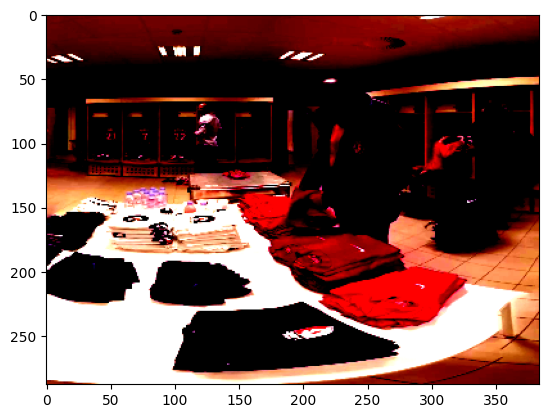

In [8]:
plt.imshow(img_timeseries[0].to("cpu").squeeze().detach().numpy().transpose(1,2,0))

In [27]:
for d in hmd_timeseries:
    print(np.array(d))

[0. 0. 0. 0.]
[0. 0. 0. 0.]
[-1.5  -0.9  -0.05 -0.03]
[0.   1.5  0.   0.05]
[-0.9  -0.3  -0.03 -0.01]
[ 0.9  -1.5   0.03 -0.05]
[4.8  0.9  0.16 0.03]
[-1.2   0.6  -0.04  0.02]
[ 0.9  -0.9   0.03 -0.03]
[4.2  1.8  0.14 0.06]
[-0.3   2.1  -0.01  0.07]
[-1.2  -0.3  -0.04 -0.01]
[-3.6   5.7  -0.12  0.19]
[-10.5    3.9   -0.35   0.13]
[-7.8   1.5  -0.26  0.05]
[-4.8   1.5  -0.16  0.05]
[-13.2    7.2   -0.44   0.24]
[-7.2   3.   -0.24  0.1 ]
[-9.6   3.9  -0.32  0.13]
[-12.     2.7   -0.4    0.09]
[-4.5   5.4  -0.15  0.18]
[-6.9   3.3  -0.23  0.11]


In [28]:
# Run the saliency model
with torch.no_grad():
    sal_preds = []
    for img in img_timeseries:
        sal_pred = unisal_model(img.unsqueeze(0))
        sal_pred = sal_process(sal_pred.cpu().detach().numpy()).squeeze()
        sal_preds.append(sal_pred)

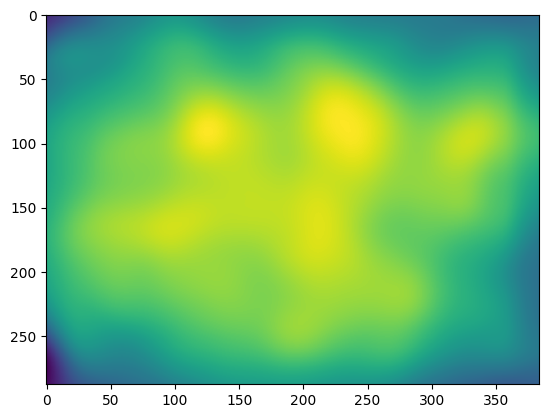

In [12]:
plt.imshow((sal_preds[0]+1/2))

In [29]:
# run the time model
with torch.no_grad():
    gaze_pred = time_model(torch.tensor(sal_preds[5:20], dtype=torch.float32).unsqueeze(0).to("cuda"), 
                           torch.tensor(hmd_timeseries[5:20], dtype=torch.float32).unsqueeze(0).to("cuda"))

In [30]:
gaze_pred

tensor([[[ 0.0035,  0.0119],
         [ 0.0043,  0.0128],
         [ 0.0018,  0.0126],
         [-0.0002,  0.0123],
         [ 0.0002,  0.0130],
         [ 0.0003,  0.0152]]], device='cuda:0')

In [32]:
np_preds = gaze_pred[0].detach().cpu().numpy()
p_horz = np_preds[:,0]*360 + horz_hmd[20]
p_vert = np_preds[:,1]*180 + vert_hmd[20]
list(zip(p_horz, p_vert))

[(26.946293, -19.444664),
 (27.214724, -19.280289),
 (26.320501, -19.315502),
 (25.614326, -19.37395),
 (25.747448, -19.243416),
 (25.768038, -18.849829)]

In [23]:
# evaluate results

list(zip(range(len(metadata)),metadata['giw_long'],metadata['giw_lat']))

[(0, 33.87, -27.23),
 (1, 33.87, -27.24),
 (2, 33.76, -27.28),
 (3, 33.78, -27.25),
 (4, 33.77, -27.29),
 (5, 33.83, -27.37),
 (6, 34.02, -27.35),
 (7, 34.02, -27.34),
 (8, 34.12, -27.35),
 (9, 34.32, -27.25),
 (10, 35.31, -27.07),
 (11, 35.27, -27.08),
 (12, 35.15, -26.88),
 (13, 14.41, -29.91),
 (14, 13.52, -25.41),
 (15, 14.76, -23.51),
 (16, 15.49, -22.49),
 (17, 15.81, -22.03),
 (18, 16.02, -21.59),
 (19, 16.02, -21.38),
 (20, 16.16, -21.19),
 (21, 16.28, -21.02)]